In [ ]:
import pandas as pd
df = pd.read_csv("OIBSIP_Retail_Sales.csv")
df.head()

,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,T0001,2023-01-01 00:00:00.000000000,CUST472,Male,45,Clothing,1,100,100
1,T0002,2023-01-01 08:44:41.081081081,CUST377,Female,24,Electronics,1,100,100
2,T0003,2023-01-01 17:29:22.162162162,CUST378,Female,52,Electronics,2,50,100
3,T0004,2023-01-02 02:14:03.243243243,CUST389,Female,45,Clothing,4,30,120
4,T0005,2023-01-02 10:58:44.324324324,CUST070,Female,31,Beauty,2,500,1000


In [ ]:
df["Date"] = pd.to_datetime(df["Date"])
print("Shape:", df.shape)
print(df.dtypes)
print("Nulls:", int(df.isnull().sum().sum()))
num = df[["Age", "Quantity", "Price per Unit", "Total Amount"]]
print(num.describe())
print("Median:")
print(num.median())
print("Mode:")
print(num.mode().iloc[0])
print("Std:")
print(num.std())

Shape: (1000, 9)
Transaction ID              object
Date                datetime64[ns]
Customer ID                 object
Gender                      object
Age                          int64
Product Category            object
Quantity                     int64
Price per Unit               int64
Total Amount                 int64
dtype: object
Nulls: 0
               Age     Quantity  Price per Unit  Total Amount
count  1000.000000  1000.000000     1000.000000   1000.000000
mean     41.394000     2.477000      181.390000    444.955000
std      13.559891     1.124605      166.958807    494.130487
min      18.000000     1.000000       25.000000     25.000000
25%      30.000000     1.000000       30.000000    100.000000
50%      41.000000     2.000000      100.000000    200.000000
75%      53.000000     3.000000      300.000000    600.000000
max      64.000000     4.000000      500.000000   2000.000000
Median:
Age                41.0
Quantity            2.0
Price per Unit    100.0
Total A

## Descriptive Statistics - Observations
- Total sales amount has a mean of 444.96 but a median of only 200. A few high-value purchases pull the average up (right-skewed data).
- Standard deviation of total amount is 494.13, so purchase values vary a lot.
- Average customer age is about 41 (range 18 to 64). Average quantity per purchase is about 2.5.
- Most common values: age 45, quantity 1, price per unit 500, total amount 100.

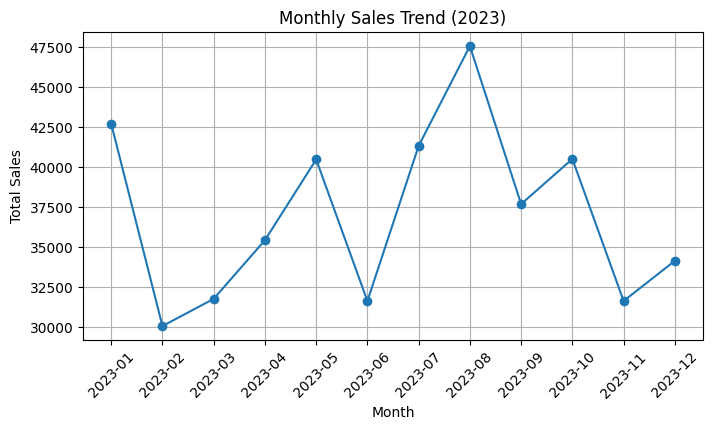

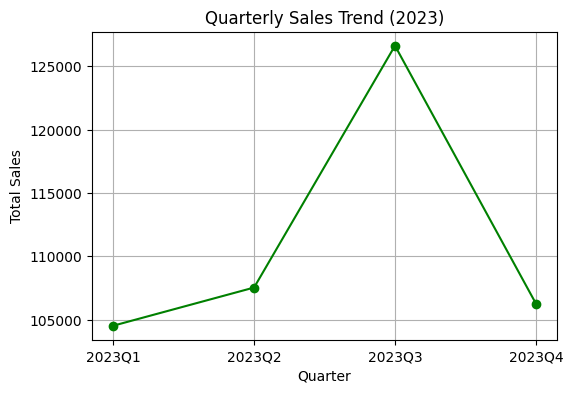

In [ ]:
import matplotlib.pyplot as plt
monthly = df.groupby(df["Date"].dt.to_period("M"))["Total Amount"].sum()
monthly.index = monthly.index.astype(str)
plt.figure(figsize=(8, 4))
plt.plot(monthly.index, monthly.values, marker="o")
plt.title("Monthly Sales Trend (2023)")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.grid(True)
plt.show()
quarterly = df.groupby(df["Date"].dt.to_period("Q"))["Total Amount"].sum()
quarterly.index = quarterly.index.astype(str)
plt.figure(figsize=(6, 4))
plt.plot(quarterly.index, quarterly.values, marker="o", color="green")
plt.title("Quarterly Sales Trend (2023)")
plt.xlabel("Quarter")
plt.ylabel("Total Sales")
plt.grid(True)
plt.show()

## Sales Trend - Observations
- August 2023 had the highest sales (47,580) and February the lowest (30,055).
- Q3 (Jul-Sep) was the strongest quarter with 126,605 in sales. The other three quarters were close to each other at around 105,000 to 108,000.
- Sales go up and down month to month without a steady rise, so there is no clear growth trend across the year.

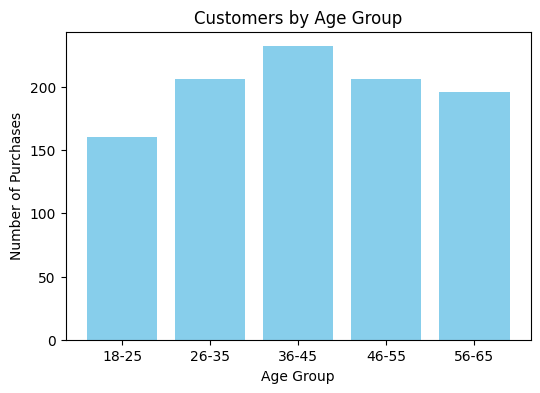

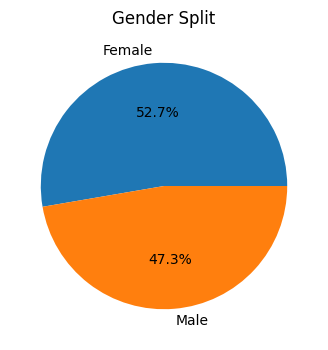

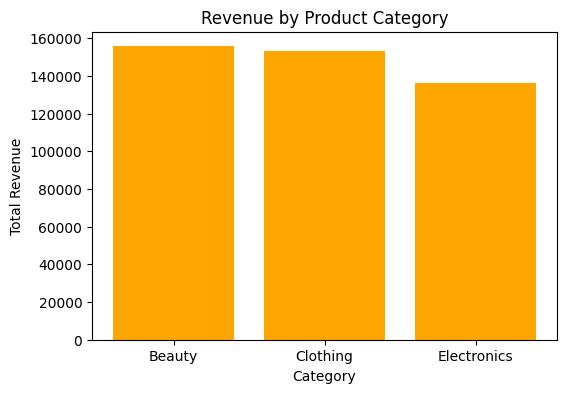

Product Category
Beauty         155675
Clothing       153270
Electronics    136010
Name: Total Amount, dtype: int64


In [ ]:
df["Age Group"] = pd.cut(df["Age"], bins=[17, 25, 35, 45, 55, 65], labels=["18-25", "26-35", "36-45", "46-55", "56-65"])
age_counts = df["Age Group"].value_counts().sort_index()
plt.figure(figsize=(6, 4))
plt.bar(age_counts.index.astype(str), age_counts.values, color="skyblue")
plt.title("Customers by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Number of Purchases")
plt.show()
gender_counts = df["Gender"].value_counts()
plt.figure(figsize=(4, 4))
plt.pie(gender_counts.values, labels=gender_counts.index, autopct="%1.1f%%")
plt.title("Gender Split")
plt.show()
cat_rev = df.groupby("Product Category")["Total Amount"].sum().sort_values(ascending=False)
plt.figure(figsize=(6, 4))
plt.bar(cat_rev.index, cat_rev.values, color="orange")
plt.title("Revenue by Product Category")
plt.xlabel("Category")
plt.ylabel("Total Revenue")
plt.show()
print(cat_rev)

## Customer Demographics and Product Analysis - Observations
- The 36-45 age group makes the most purchases (232) and brings the highest revenue (107,660). The 18-25 group is the smallest (160 purchases).
- Female customers made 527 purchases and male customers 473. Female customers also generated more revenue (240,760 vs 204,195).
- Beauty earns the most revenue (155,675), followed by Clothing (153,270) and Electronics (136,010).
- Clothing sells the most units (875), but Beauty earns more because its average order value is higher (469 vs 431).
- The dataset has only 3 product categories and no product names, so the analysis is done at category level instead of a top 10 product list.